# Simulador de Radiografia Policromática de Nêutrons (Baseado no NEUIT)

Este notebook está estruturado em **6 etapas modulares**:
1. **Espectro do Feixe $\Phi(\lambda)$:** Seleção da distribuição espectral (experimental CG-1D ou Maxwell-Boltzmann).
2. **Banco Híbrido de Seções de Choque $\Sigma_i(\lambda)$:** Cristais com *Bragg-edges* (`braggedgemodeling`) + Compostos/Gases/Absorvedores (`ImagingReso` / ENDF/B-VIII).
3. **Geometria 2D ($512 \times 512$), Ângulo Sólido e Colimador:** Perfil espacial divergente ($\cos^4\theta$ + penumbra cônica) e caminho oblíquo no ar atmosférico.
4. **Simulação do Flat-Field (*Open Beam* no Ar):** Imagem de feixe aberto $I_{\mathrm{flat}}(x, y)$ sem amostra.
5. **Construção do Phantom (Step-Wedge de Ferro) e Imagem Bruta:** Inserção da amostra no feixe e geração de $I_{\mathrm{bruta}}(x, y)$.
6. **Normalização Experimental (Flat/Dark Correction) e Validação:** Recuperação da transmissão $T(x, y)$ e comparação com a curva teórica do NEUIT.

---
## Parte 1: Importações, Grade de Comprimento de Onda e Espectro do Feixe $\Phi(\lambda)$

In [37]:
import os
from PIL import Image
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
import random

from ImagingReso.resonance import Resonance
import ImagingReso._utilities as ir_util
from braggedgemodeling import xscalc, matter

# 1.1 Grade de Comprimento de Onda (0.5 a 10.0 Angstroms) e conversão para Energia (eV)
lmbda_A = np.linspace(0.5, 10.0, 300)
energia_eV = ir_util.angstroms_to_ev(lmbda_A)  # E(eV) = 0.081804 / lambda^2

# 1.2 Seletor de Espectro (IEA-R1, CG-1D ou Maxwelliano)
def carregar_espectro(tipo='IEAR1', temp_K=293.6, caminho_neuit='/home/carlos/Desktop/projetos/NEUIT', arquivo_custom=None):
    """
    Opções de 'tipo':
      - 'IEAR1'           : Espectro do reator IEA-R1 (static/instrument_file/beam_flux_iear1.csv)
      - 'CG1D'            : Espectro experimental da linha CG-1D (HFIR/ORNL) incluso no NEUIT
      - 'Maxwell_Termico' : Espectro Maxwelliano térmico (T = 300 K, pico ~ 1.8 Å)
      - 'Maxwell_Frio'    : Espectro Maxwelliano de fonte fria (T = 40 K, pico ~ 4.8 Å)
      - 'Custom'          : Arquivo CSV/TXT próprio de 2 colunas (wavelength_A ou energy_eV, flux)
    """
    arquivo_alvo = None
    if tipo == 'IEAR1':
        arq_iear1 = os.path.join(caminho_neuit, 'static', 'instrument_file', 'beam_flux_iear1.csv')
        if os.path.exists(arq_iear1):
            arquivo_alvo = arq_iear1
    elif tipo == 'CG1D':
        arquivos_neuit = glob.glob(os.path.join(caminho_neuit, '**', '*cg1d*.txt'), recursive=True) + \
                         glob.glob(os.path.join(caminho_neuit, '**', '*spectrum*.txt'), recursive=True)
        if arquivos_neuit:
            arquivo_alvo = arquivos_neuit[0]
    elif tipo == 'Custom' and arquivo_custom is not None:
        arquivo_alvo = arquivo_custom

    if arquivo_alvo is not None:
        df_spec = pd.read_csv(arquivo_alvo, sep=None, engine='python', comment='#')
        col_x, col_y = df_spec.columns[0], df_spec.columns[1]
        x_raw = df_spec[col_x].values.astype(float)
        y_raw = df_spec[col_y].values.astype(float)
        # Se a 1ª coluna estiver em Energia (eV), converte para Comprimento de Onda (Å) e ordena:
        if 'energy' in col_x.lower() or 'ev' in col_x.lower():
            x_raw = ir_util.ev_to_angstroms(x_raw)
        elif np.max(x_raw) < 1e-6:
            x_raw = x_raw * 1e10
        ordem = np.argsort(x_raw)
        x_raw, y_raw = x_raw[ordem], y_raw[ordem]
        fluxo = np.interp(lmbda_A, x_raw, y_raw, left=0.0, right=0.0)
        print(f"Espectro carregado do arquivo: {os.path.basename(arquivo_alvo)} (coluna X original: '{col_x}')")
        return fluxo / np.trapz(fluxo, lmbda_A)

    if tipo == 'Maxwell_Frio':
        temp_K = 40.0
    const_T = 949.0 / temp_K  # h^2 / (2 * m_n * k_B * T) em Angstrom^2
    fluxo = (1.0 / (lmbda_A**5)) * np.exp(-const_T / (lmbda_A**2))
    print(f"Espectro analítico gerado: {tipo} (T = {temp_K} K)")
    return fluxo / np.trapz(fluxo, lmbda_A)

# Carrega o espectro do reator IEA-R1 (e o CG-1D / Térmico para comparação)
phi_iear1   = carregar_espectro(tipo='IEAR1')
phi_termico = carregar_espectro(tipo='Maxwell_Termico', temp_K=300.0)
phi_frio    = phi_iear1  # Usa o espectro do IEA-R1 nas simulações de radiografia abaixo
pesos_term  = phi_termico / np.trapz(phi_termico, lmbda_A)
pesos_frio  = phi_frio    / np.trapz(phi_frio, lmbda_A)

Espectro carregado do arquivo: beam_flux_iear1.csv (coluna X original: 'energy_eV')
Espectro analítico gerado: Maxwell_Termico (T = 300.0 K)


---
## Parte 2: Banco Híbrido de Seções de Choque Macroscópicas $\Sigma_i(\lambda)$
- **Cristais (`Fe`, `Al`, `Cu`):** Calculados via `braggedgemodeling` (Tese de Sven Vogel + `periodictable`), incluindo espalhamento elástico coerente (*Bragg-edges*), incoerente, inelástico e absorção.
- **Amorfos, Gases e Absorvedores (`H2O`, `Ar_atm`, `Gd`, `B4C`):** Calculados via `ImagingReso` usando o banco nuclear avaliado **ENDF/B-VIII**.

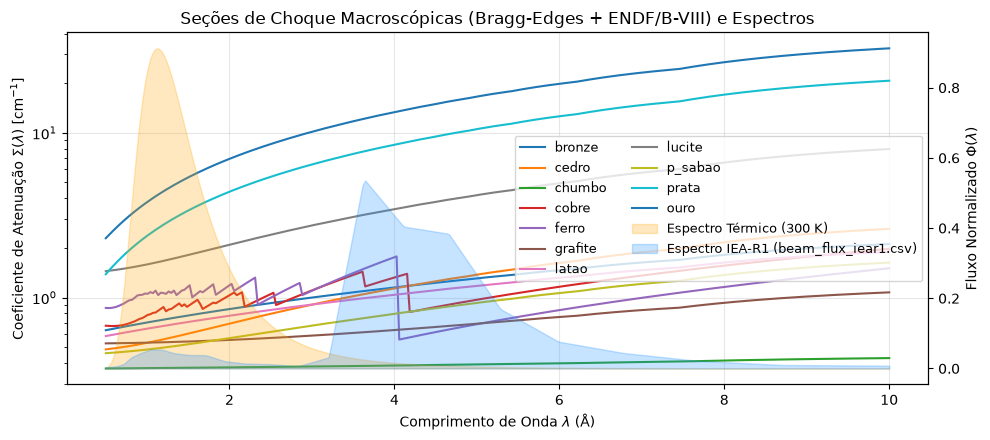

In [44]:
def obter_curvas_sigma_neuit(lmbda_grid):
    sigmas_lambda = {}
    
    # 2A) Materiais Cristalinos via BraggEdgeModeling (inclui Bragg-edges coerentes!)
    cristais = {
        'Fe': {'a': 2.866, 'sgid': 229, 'atoms': [('Fe', (0, 0, 0)), ('Fe', (0.5, 0.5, 0.5))]},  # CCC (BCC)
        'Al': {'a': 4.049, 'sgid': 225, 'atoms': [('Al', (0, 0, 0)), ('Al', (0.5, 0.5, 0)), ('Al', (0.5, 0, 0.5)), ('Al', (0, 0.5, 0.5))]},  # CFC (FCC)
        'Cu': {'a': 3.615, 'sgid': 225, 'atoms': [('Cu', (0, 0, 0)), ('Cu', (0.5, 0.5, 0)), ('Cu', (0.5, 0, 0.5)), ('Cu', (0, 0.5, 0.5))]},  # CFC (FCC)
    }
    for mat_cristal, dados in cristais.items():
        a = dados['a']
        lattice = matter.Lattice(a=a, b=a, c=a, alpha=90.0, beta=90.0, gamma=90.0)
        atoms = [matter.Atom(el, xyz) for el, xyz in dados['atoms']]
        estrutura = matter.Structure(atoms, lattice, sgid=dados['sgid'])
        
        calc_xs = xscalc.XSCalculator(estrutura, T=293.6)
        sigma_barns_uc = np.real(calc_xs.xs(lmbda_grid))  # barns por célula unitária
        # 1 barn / Å³ = 1e-24 cm² / 1e-24 cm³ = 1 cm⁻¹
        sigmas_lambda[mat_cristal] = sigma_barns_uc / estrutura.lattice.volume  # em cm^-1
        
    # 2B) Materiais Amorfos / Gases / Absorvedores via ImagingReso (ENDF/B-VIII)
    e_crescente = ir_util.angstroms_to_ev(lmbda_grid[::-1])
    o_reso = Resonance(energy_min=float(e_crescente[0]), energy_max=float(e_crescente[-1]),
                       energy_step=float((e_crescente[-1]-e_crescente[0])/500.0), database='ENDF_VIII')
    
    compostos = {
        'H2O': 1.00,
        'Gd': 7.90,
        'B4C': 2.52,
        'N156O42Ar1': 0.001204,  # Ar atmosférico seco (1 atm, 20 °C)
    }
    materiais_labels = {
        "bronze":  {"formula": "Cu88Sn12",     "rho": 8.80},
        "cedro":   {"formula": "C6H10O5",      "rho": 0.50},
        "chumbo":  {"formula": "Pb",           "rho": 11.34},
        "grafite": {"formula": "C",            "rho": 2.20},
        "latao":   {"formula": "Cu65Zn35",     "rho": 8.50},
        "lucite":  {"formula": "C5O2H8",       "rho": 1.19},
        "p_sabao": {"formula": "Mg3Si4O12H2",  "rho": 2.70},  # Sem parênteses para o ImagingReso
        "prata":   {"formula": "Ag",           "rho": 10.49},
        "ouro":    {"formula": "Au",           "rho": 19.30},
    }

    for nome, info in materiais_labels.items():
        o_reso.add_layer(formula=info["formula"], thickness=10.0, density=info["rho"])

    for formula, rho in compostos.items():
        o_reso.add_layer(formula=formula, thickness=10.0, density=rho)

    e_reso = o_reso.total_signal['energy_eV']
    
    # Salva compostos originais
    for formula in compostos.keys():
        T_1cm = o_reso.stack_signal[formula]['transmission']
        sigma_e = -np.log(np.clip(T_1cm, 1e-15, 1.0))
        sigmas_lambda[formula] = np.interp(ir_util.angstroms_to_ev(lmbda_grid), e_reso, sigma_e)
    sigmas_lambda['Ar_atm'] = sigmas_lambda['N156O42Ar1']

    # 👇 Salva todos os materiais do arquivo 'labels' pelo nome em português:
    for nome, info in materiais_labels.items():
        formula = info["formula"]
        T_1cm = o_reso.stack_signal[formula]['transmission']
        sigma_e = -np.log(np.clip(T_1cm, 1e-15, 1.0))
        sigmas_lambda[nome] = np.interp(ir_util.angstroms_to_ev(lmbda_grid), e_reso, sigma_e)

    # Mapeia 'ferro' e 'cobre' (que já foram calculados via BraggEdgeModeling)
    sigmas_lambda['ferro'] = sigmas_lambda['Fe']
    sigmas_lambda['cobre'] = sigmas_lambda['Cu']

    return sigmas_lambda

sigmas_lmbda = obter_curvas_sigma_neuit(lmbda_A)

# Plota os Espectros + Curvas de Atenuação com Bragg-Edges
fig, ax1 = plt.subplots(figsize=(10, 4.5))
for mat in ['bronze', 'cedro', 'chumbo', 'cobre', 'ferro', 'grafite', 'latao', 'lucite', 'p_sabao', 'prata', 'ouro']:
    ax1.plot(lmbda_A, sigmas_lmbda[mat], lw=1.5, label=mat)
ax1.set_xlabel(r"Comprimento de Onda $\lambda$ (Å)")
ax1.set_ylabel(r"Coeficiente de Atenuação $\Sigma(\lambda)$ [$\mathrm{cm}^{-1}$]")
ax1.set_yscale('log')
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.fill_between(lmbda_A, phi_termico, color='orange', alpha=0.25, label="Espectro Térmico (300 K)")
ax2.fill_between(lmbda_A, phi_frio, color='dodgerblue', alpha=0.25, label="Espectro IEA-R1 (beam_flux_iear1.csv)")
ax2.set_ylabel(r"Fluxo Normalizado $\Phi(\lambda)$")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='center right', ncol=2, fontsize=9)
plt.title("Seções de Choque Macroscópicas (Bragg-Edges + ENDF/B-VIII) e Espectros")
plt.tight_layout()
plt.show()

In [41]:
# Carrega os labels dinamicamente do arquivo

LABELS_MATERIAIS = {}
with open("labels", "r") as f:
    for linha in f:
        partes = linha.strip().split()
        if len(partes) == 2:
            LABELS_MATERIAIS[partes[0]] = int(partes[1])

print("Classes mapeadas:")
for mat, idx in LABELS_MATERIAIS.items():
    print(f"  {idx:2d}: {mat}")

Classes mapeadas:
   1: bronze
   2: cedro
   3: chumbo
   4: cobre
   5: ferro
   6: grafite
   7: latao
   8: lucite
   9: p_sabao
  10: prata
  11: ouro


---
## Parte 3: Grade do Detector ($512 \times 512$), Ângulo Sólido ($\cos^4\theta$) e Tubo Colimador
Modela a divergência geométrica do feixe saindo da abertura colimadora a uma distância $L$ do detector plano:
- **Lei do Ângulo Sólido:** $\Omega(x, y) \propto \cos^4\theta$, onde $\cos\theta = \frac{L}{\sqrt{L^2 + r^2}}$.
- **Penumbra Cônica do Colimador:** Região central de *umbra* ($r \le R_{\mathrm{umbra}}$) seguida pela queda gradual de penumbra até a borda do tubo ($R_{\mathrm{borda}}$).
- **Caminho Oblíquo no Ar Atmosférico:** $d_{\mathrm{ar}}(x, y) = \frac{d_{\mathrm{ar}, 0}}{\cos\theta}$.

In [29]:
# 3.1 Parâmetros Reais do Sistema do Reator IEA-R1 (BH14 - Dissertação R. M. Schoueri, 2016)
N_pix = 512                # Sensor CCD ANDOR iKon-M (16 bits, -20 °C) operando em 512 x 512 pixels
FOV_cm = 13.0              # Campo de visão (FOV): 13 cm x 13 cm (Pixel efetivo = 254 µm)
pixel_cm = FOV_cm / N_pix  # Tamanho efetivo do pixel: 0.02539 cm = 254 µm

# Geometria do Conjunto Colimador + Diafragmas no BH14 (Seções 2.2.3.1 a 2.2.3.4, pp. 32-34):
# - Tubo colimador: 116 cm (Ø 4,5") + 175 cm (Ø 5,5") = 291 cm (contém 25 cm de filtro de Bismuto)
# - Colimador interno de nêutrons: 132 cm de comprimento (Ø 3,5" = 8,89 cm na saída)
# - 3 Diafragmas de 20 cm cada (Ø 10 cm, 11 cm e 12 cm, abrindo até Ø máx 16 cm na Tabela 2.2)
L_colimador_cm = 291.0     # Comprimento do tubo colimador no BH14 (cm)
distancia_ar_cm = 80    # Trecho de ar livre entre a saída do colimador (após a seção de água) e o cintilador (cm)
diametro_feixe_cm = 12.0   # Diâmetro definido pelo 3º diafragma próximo ao objeto: 12 cm (Raio = 6.0 cm)

# Parâmetros de Intensidade em 16 bits calibrados pelos perfis reais do Flat-Field (perfil_256_x e perfil_256_y)
I0_centro = 55300          # Amplitude do feixe aberto (pico experimental ~55.340 contagens após 80 cm de ar)
I_dark = 3100              # Patamar de fundo escuro fora do feixe nos perfis 16 bits (~2.100 a 3.400 contagens)
Ui_um = 205.0              # Melhor resolução espacial intrínseca obtida: Ui = 205 ± 24 µm (Tabela 2.1 e 2.2)
psf_sigma = (Ui_um / 1e4) / pixel_cm  # Borramento óptico em pixels (~0.81 pixels)

# 3.2 Malha de Coordenadas Físicas (X, Y) em cm (-6.5 cm a +6.5 cm)
coords = np.linspace(-FOV_cm / 2, FOV_cm / 2, N_pix)
X, Y = np.meshgrid(coords, coords)
ext = [-FOV_cm / 2, FOV_cm / 2, -FOV_cm / 2, FOV_cm / 2]

# Centros ópticos medidos diretamente dos perfis 16 bits (perfil_256_x / perfil_256_y) e da máscara 512x512:
# - Centro horizontal do feixe e do diafragma: xc = 240.8 px -> x0 = -0.373 cm
# - Pico de intensidade máxima do feixe (perfil_256_x): yc_feixe = 200.8 px -> y0_feixe = +1.390 cm
# - Centro geométrico do 3º diafragma (Ø 12,44 cm, borda da máscara): yc_diaf = 178.7 px -> y0_diaf = +1.950 cm
x0 = -0.373                # Centro horizontal do feixe no detector (cm)
y0_feixe = 1.390           # Centro vertical do pico de intensidade do feixe (linha 201 px)
y0_diaf = 1.950            # Centro vertical do 3º diafragma que recorta a máscara (linha 179 px)
y0 = y0_diaf               # Referência geométrica do centro da máscara
R_mascara_cm = 6.231       # Raio equivalente da máscara binária do flat-field (245.4 pixels)

R_radial = np.sqrt((X - x0)**2 + (Y - y0_feixe)**2)  # Distância radial ao eixo de intensidade máxima
R_diaf   = np.sqrt((X - x0)**2 + (Y - y0_diaf)**2)   # Distância radial ao centro do 3º diafragma

# 3.3 Fator de Ângulo Sólido: cos(theta) = L / sqrt(L^2 + r^2)
cos_theta = L_colimador_cm / np.sqrt(L_colimador_cm**2 + R_radial**2)
fator_angulo_solido = cos_theta**4

# 3.4 Perfil Radial em Dois Estágios Físicos (Colimador + 3º Diafragma) calibrado pelos perfis 16 bits:
# 1º Estágio: Queda suave da penumbra do tubo colimador centrada em (x0, y0_feixe)
R_col = 7.40
perfil_colimador = np.clip(1.0 - (R_radial / R_col)**1.75, 0.0, 1.0)

# 2º Estágio: Corte abrupto da borda circular do 3º diafragma (Raio = 6.22 cm, difusão = 0.24 cm)
R_borda_diaf, dr_diaf = 6.22, 0.24
perfil_diafragma = 1.0 / (1.0 + np.exp((R_diaf - R_borda_diaf) / dr_diaf))

# Sombra superior da janela no topo do detector
corte_superior = 1.0 / (1.0 + np.exp((Y - 6.85) / 0.45))

perfil_feixe = fator_angulo_solido * perfil_colimador * perfil_diafragma * corte_superior

# Máscara geométrica do feixe aberto idêntica à máscara real (0 = dentro do feixe, 77 = fora;
# corresponde à isófota experimental I_flat >= 11.750 contagens nos perfis de 16 bits)
limiar_mascara = 0.165
mascara_flat_beam = np.where(perfil_feixe >= limiar_mascara, 0, 77).astype(np.uint8)
print(f"IEA-R1 (BH14): Grade = {N_pix}x{N_pix} | Pico = ({x0:+.2f}, {y0_feixe:+.2f}) cm | Diafragma = ({x0:+.2f}, {y0_diaf:+.2f}) cm | R_mask = {R_mascara_cm:.2f} cm")

IEA-R1 (BH14): Grade = 512x512 | Pico = (-0.37, +1.39) cm | Diafragma = (-0.37, +1.95) cm | R_mask = 6.23 cm


---
## Parte 4: Simulação do Flat-Field (*Open Beam* no Ar Atmosférico — Sem Amostra)
Calcula a transmissão policromática do ar atmosférico $T_{\mathrm{ar}}(x, y)$ em cada pixel e gera a imagem de feixe aberto $I_{\mathrm{flat}}(x, y)$.

Transmissão no eixo central (80 cm de ar): 94.47%


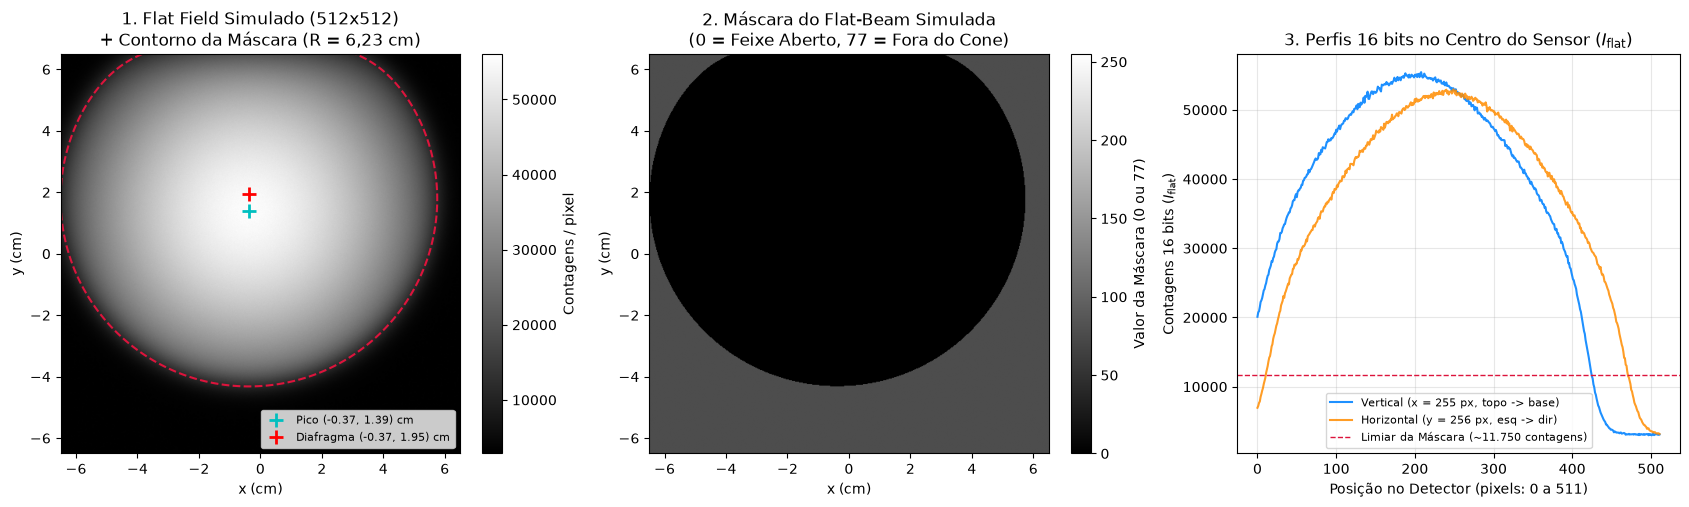

In [30]:
# 4.1 Caminho oblíquo percorrido pelo feixe no ar atmosférico em cada pixel (sem amostra)
d_ar_flat_2d = distancia_ar_cm / cos_theta

# 4.2 Etapa de Transmissão Policromática do NEUIT apenas para o Ar Atmosférico
T_ar_2d = np.trapz(
    pesos_frio[:, None, None] * np.exp(-sigmas_lmbda['Ar_atm'][:, None, None] * d_ar_flat_2d[None, :, :]),
    lmbda_A, axis=0
)
print(f"Transmissão no eixo central ({distancia_ar_cm:.0f} cm de ar): {T_ar_2d.max()*100:.2f}%")

# 4.3 Resposta do Detector: Contagens do Flat-Field (PSF Gaussiana + Estatística de Poisson)
mapa_ideal_flat = I_dark + (I0_centro * perfil_feixe * T_ar_2d)
flat_image = np.random.poisson(gaussian_filter(mapa_ideal_flat, sigma=psf_sigma)).astype(np.float32)

# 4.4 Visualização: Flat Image Simulado vs. Máscara do Flat-Beam vs. Perfis Espaciais
fig, axes = plt.subplots(1, 3, figsize=(17, 5.0))

im0 = axes[0].imshow(flat_image, cmap='gray', extent=ext, origin='lower')
axes[0].contour(X, Y, perfil_feixe, levels=[limiar_mascara], colors='crimson', linewidths=1.5, linestyles='--')
axes[0].plot(x0, y0_feixe, 'c+', markersize=10, markeredgewidth=2, label=f'Pico ({x0:.2f}, {y0_feixe:.2f}) cm')
axes[0].plot(x0, y0_diaf,  'r+', markersize=10, markeredgewidth=2, label=f'Diafragma ({x0:.2f}, {y0_diaf:.2f}) cm')
axes[0].set_title("1. Flat Field Simulado (512x512)\n+ Contorno da Máscara (R = 6,23 cm)")
axes[0].set_xlabel("x (cm)")
axes[0].set_ylabel("y (cm)")
axes[0].legend(loc='lower right', fontsize=8.0)
plt.colorbar(im0, ax=axes[0], fraction=0.046, label="Contagens / pixel")

im1 = axes[1].imshow(mascara_flat_beam, cmap='gray', vmin=0, vmax=255, extent=ext, origin='lower')
axes[1].set_title("2. Máscara do Flat-Beam Simulada\n(0 = Feixe Aberto, 77 = Fora do Cone)")
axes[1].set_xlabel("x (cm)")
axes[1].set_ylabel("y (cm)")
plt.colorbar(im1, ax=axes[1], fraction=0.046, label="Valor da Máscara (0 ou 77)")

# Perfis na orientação matricial de imagem (0 = topo/esquerda -> 511 = base/direita), idênticos a perfil_256_x e perfil_256_y
flat_img_topdown = np.flipud(flat_image)
pix_idx = np.arange(N_pix)
axes[2].plot(pix_idx, flat_img_topdown[:, 255], color='dodgerblue', lw=1.5, label="Vertical (x = 255 px, topo -> base)")
axes[2].plot(pix_idx, flat_img_topdown[256, :], color='darkorange', lw=1.5, alpha=0.85, label="Horizontal (y = 256 px, esq -> dir)")
axes[2].axhline(11750, color='crimson', ls='--', lw=1.0, label="Limiar da Máscara (~11.750 contagens)")
axes[2].set_title(r"3. Perfis 16 bits no Centro do Sensor ($I_{\mathrm{flat}}$)")
axes[2].set_xlabel("Posição no Detector (pixels: 0 a 511)")
axes[2].set_ylabel(r"Contagens 16 bits ($I_{\mathrm{flat}}$)")
axes[2].legend(fontsize=8.0)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

float64 (512, 512) 1568.0 59263.0


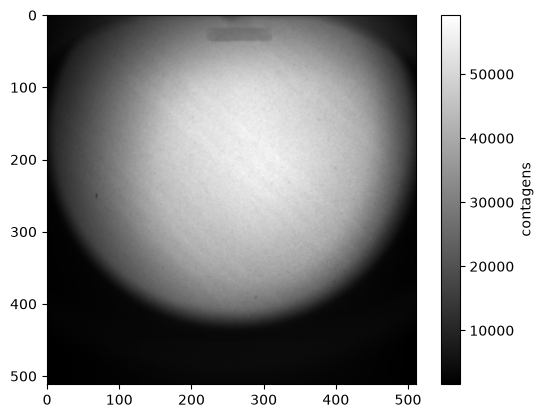

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

dire = "flat_field/"

img = np.array(Image.open(dire+"1006.tif")).astype(np.float64)
print(img.dtype, img.shape, img.min(), img.max())

plt.imshow(img, cmap ="gray")
plt.colorbar(label="contagens")
plt.show()

In [32]:
import glob, os 

arq = sorted(glob.glob(dire+"*.tif"))

pilha = []
i = []
for f in arq:
    img = np.array(Image.open(f)).astype(np.float64)
    ids = os.path.basename(f)
    i.append(ids)
    pilha.append(img)

pilha = np.array(pilha)
pilha.shape
flat_medio = pilha.mean(axis=0)

In [34]:
import pandas as pd
stats = pd.DataFrame({
    "arquivo": ids,
    "media":   pilha.mean(axis=(1, 2)),
    "desvio":  pilha.std(axis=(1, 2)),
    "maximo":  pilha.max(axis=(1, 2)),
    "centro":  pilha[:, 256, 255],   # pixel (x=255, y=256)
})

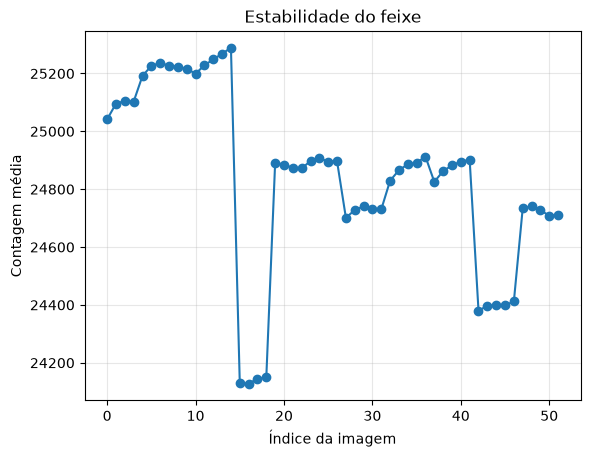

In [26]:
plt.plot(stats["media"], "o-")
plt.xlabel("Índice da imagem")
plt.ylabel("Contagem média")
plt.title("Estabilidade do feixe")
plt.grid(alpha=0.3)
plt.show()

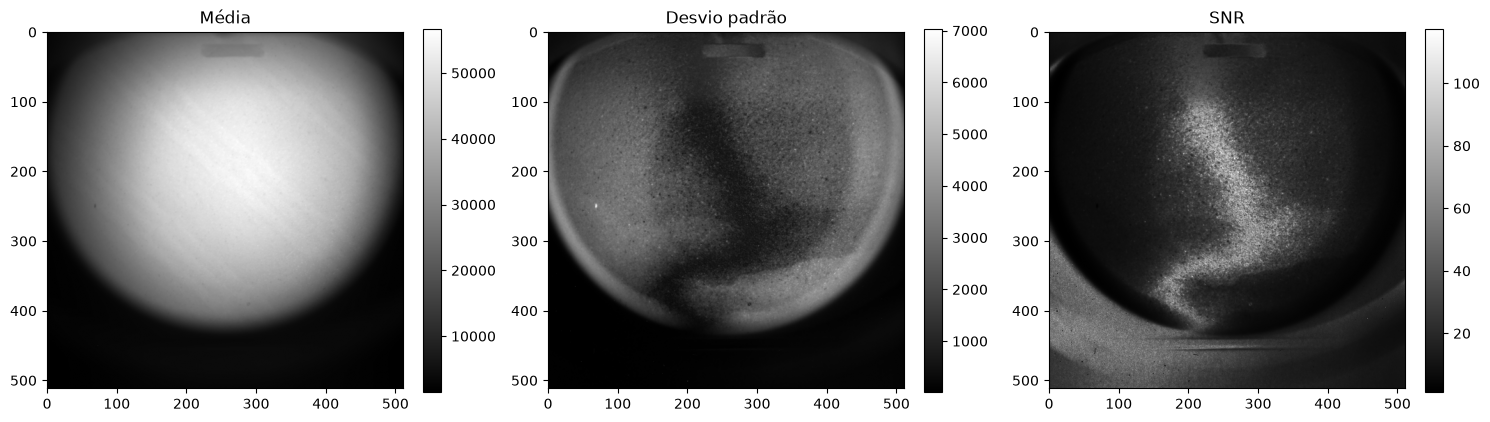

Pixels dentro do feixe: 174337


In [35]:
flat_medio = pilha.mean(axis=0)                  # reduz o ruído de Poisson
flat_std   = pilha.std(axis=0)
snr        = flat_medio / np.maximum(flat_std, 1e-9) # Signal-to-Noise Ratio

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for a, d, t in zip(ax, [flat_medio, flat_std, snr], ["Média", "Desvio padrão", "SNR"]):
    h = a.imshow(d, cmap="gray")
    a.set_title(t)
    plt.colorbar(h, ax=a, fraction=0.046)
plt.tight_layout()
plt.show()

# máscara do feixe: mesma isófota de ~11.750 contagens
mascara_feixe = flat_medio >= 11750
print("Pixels dentro do feixe:", mascara_feixe.sum())

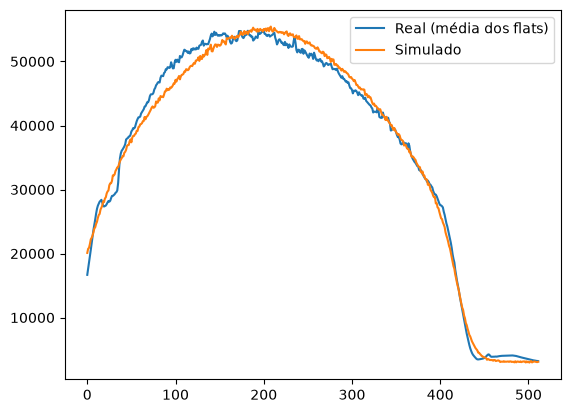

In [36]:
plt.plot(flat_medio[:, 255], label="Real (média dos flats)")
plt.plot(flat_image[::-1][:, 255], label="Simulado")   # flipud, para ficar no sentido topo → base
plt.legend()
plt.show()

---
## Parte 5: Construção do Phantom (Step-Wedge de Ferro) e Radiografia Bruta $I_{\mathrm{bruta}}(x, y)$
Posiciona um *Step-Wedge* de Ferro (`Fe`) com 5 degraus de espessura ($0{,}2$ a $2{,}0\text{ cm}$) dentro do feixe e calcula a imagem radiográfica bruta registrada pelo detector.

In [48]:
def gerador_amostra(X, Y):
    N_pix = 512
    d_rand = np.zeros((N_pix, N_pix), dtype=np.float32)

    # sorteio dos materiais 
    material_sorteado = random.choice(list(LABELS_MATERIAIS.keys()))
    id_sorteado = LABELS_MATERIAIS[material_sorteado]

    id_geo = [1,2,3]

    geo = random.choice(id_geo)

    if geo == 1: # step edge
        n = np.random.randint(1, 6)
        degraus_cm = np.random.uniform(0.1,2.0,n)
        x_i, x_f =  -np.random.uniform(0.1,2), np.random.uniform(0.1,2)
        y_base, alt_degrau = np.random.uniform(-2.5,0), np.random.uniform(0.5, 1.5)

        for i, esp_cm in enumerate(degraus_cm):
            y_inf = y_base + i * alt_degrau
            y_sup = y_base + (i + 1) * alt_degrau
            mask_degrau = (X >= x_i) & (X <= x_f) & (Y >= y_inf) & (Y < y_sup)
            d_rand[mask_degrau] = esp_cm
    
    elif  geo == 2:
        '''
        MOEDA VISTA DE FRENTE 
        '''
        xc = np.random.uniform(-1,1)
        yc = np.random.uniform(-1,1)
        raio_cm = np.random.uniform(0.5, 1.5)
        espessura = np.random.uniform(0.2, 2.0)

        mask_moeda = (X - xc)**2 + (Y - yc)**2 <= raio_cm**2
        d_rand[mask_moeda] = espessura

    elif geo == 3:
        '''
        Cilindro em pé 
        '''
        n = np.random.randint(1,4)
        xc, yc = np.random.uniform(-1,1), np.random.uniform(-1,1)
        raios_cm = np.random.uniform(0.1,2.0,n)
        alt_degrau = np.random.uniform(0.5, 1.5)

        for i, raio_cm in enumerate(raios_cm):
            y_inf = yc + i * alt_degrau
            y_sup = yc + (i + 1) * alt_degrau
            dx2 = (X - xc)**2
            mask = (dx2 <= raio_cm**2) & (Y >= y_inf) & (Y < y_sup)
            d_rand[mask] = 2.0 * np.sqrt(raio_cm**2 - dx2[mask])

                   
    
    return d_rand, material_sorteado, id_sorteado
        

    

In [46]:
def radiografia(amostra, distancia_ar_cm, material):
    d_ar_com_amostra = (distancia_ar_cm - amostra) / cos_theta
    d_amostra = amostra/cos_theta


    # 5.2 Etapa de Transmissão Policromática do NEUIT (Ar + Step-Wedge de Ferro)
    tau_total = (
        sigmas_lmbda['Ar_atm'][:, None, None] * d_ar_com_amostra[None, :, :] +
        sigmas_lmbda[f'{material}'][:, None, None]     * d_amostra[None, :, :]
    )
    T_amostra_ar_2d = np.trapz(pesos_frio[:, None, None] * np.exp(-tau_total), lmbda_A, axis=0)
    

    # 5.3 Imagem Radiográfica Bruta no Detector (I_bruta com Ângulo Sólido + PSF + Poisson)
    mapa_ideal_amostra = I_dark + (I0_centro * perfil_feixe * T_amostra_ar_2d)
    img_bruta = np.random.poisson(gaussian_filter(mapa_ideal_amostra, sigma=psf_sigma)).astype(np.float32)


    # 7.1 Dicionário de classes conforme o arquivo 'labels' em anexo (0 = fundo)
    LABELS_MATERIAIS = {
    'fundo':   0,
    'bronze':  1,
    'cedro':   2,
    'chumbo':  3,
    'cobre':   4,
    'ferro':   5,
    'grafite': 6,
    'latao':   7,
    'lucite':  8,
    'p_sabao': 9,
    'prata':   10,
    'ouro':    11,
}

    # 7.2 Construção da máscara para U-Net (somente 0 = fundo e o label do material respectivo):
    mascara_objeto = np.full((N_pix, N_pix), LABELS_MATERIAIS['fundo'], dtype=np.uint8)  # 0 = fundo
    mascara_objeto[amostra > 0] = LABELS_MATERIAIS[f'{material}']                       

    # 7.3 Preparação das matrizes para exportação (orientação de imagem: linha 0 no topo com np.flipud)
    img_bruta_32b = np.flipud(img_bruta).astype(np.float32)       # Imagem de entrada em 32 bits (float32)
    mascara_8b    = np.flipud(mascara_objeto).astype(np.uint8)    # Máscara para U-Net (apenas 0 e 5)
    
    return img_bruta_32b, mascara_8b



In [52]:
from tqdm import tqdm  

# Looping gerando as imagens
n_imagens = 300
contador = {'bronze':  0,
    'cedro':   0,
    'chumbo':  0,
    'cobre':   0,
    'ferro':   0,
    'grafite': 0,
    'latao':   0,
    'lucite':  0,
    'p_sabao': 0,
    'prata':   0,
    'ouro':    0,}

pasta_saida = "saida_tiff"
os.makedirs(pasta_saida, exist_ok=True)
os.makedirs(pasta_saida+"/img", exist_ok=True)
os.makedirs(pasta_saida+"/mask", exist_ok=True)

for i in tqdm(range(n_imagens), desc="Gerando radiografias"):
    malha, material, id_sorteado =gerador_amostra(X, Y)
    img, mask = radiografia(malha, distancia_ar_cm, material)

    contador[material] += 1

    caminho_bruta_tiff = os.path.join(pasta_saida+"/img", f"{i}.tiff")
    caminho_mask_tiff  = os.path.join(pasta_saida+"/mask", f"{i}.tiff")

    # mode='F' -> TIFF de 32-bit ponto flutuante (IEEE754 float32)
    # mode='L' -> TIFF de 8-bit inteiro sem sinal (uint8, ideal para classes 0..11 na U-Net)
    Image.fromarray(img, mode='F').save(caminho_bruta_tiff, format='TIFF')
    Image.fromarray(mask,    mode='L').save(caminho_mask_tiff,  format='TIFF')


pwd_img, pwd_mask = "saida_tiff/img", "saida_tiff/mask"

print("Contagem por material",contador)
print("Total salvo (img, mask):",
len(os.listdir(pwd_img)), 
len(os.listdir(pwd_mask)))



Gerando radiografias:   0%|          | 0/300 [00:00<?, ?it/s]

Gerando radiografias: 100%|██████████| 300/300 [07:26<00:00,  1.49s/it]

Contagem por material {'bronze': 26, 'cedro': 34, 'chumbo': 34, 'cobre': 20, 'ferro': 28, 'grafite': 27, 'latao': 25, 'lucite': 25, 'p_sabao': 25, 'prata': 26, 'ouro': 30}
Total salvo (img, mask): 300 300


In [ ]:
# 5.1 Construção do Phantom 2D: Cunha com Degraus de Ferro da Dissertação (Fig. 2.29, p. 48)
#     Dimensões reais da cunha: 20 mm (2.0 cm) de largura x 60 mm (6.0 cm) de altura total
#     6 degraus de 10 mm (1.0 cm) de altura cada, com espessuras de 2, 4, 6, 8, 10 e 12 mm
d_Fe_2d = np.zeros((N_pix, N_pix), dtype=np.float32)
degraus_cm = [0.2, 0.4, 0.6, 0.8, 1.0, 1.2]  # Espessuras: 2, 4, 6, 8, 10, 12 mm

x_ini, x_fim = -1.0, 1.0                      # Largura real da cunha (Fig. 2.29): 20 mm = 2.0 cm
y_base, alt_degrau = -2.5, 1.0                # 6 degraus de 1.0 cm = 60 mm (6.0 cm) de altura total

for i, esp_cm in enumerate(degraus_cm):
    y_inf = y_base + i * alt_degrau
    y_sup = y_base + (i + 1) * alt_degrau
    mask_degrau = (X >= x_ini) & (X <= x_fim) & (Y >= y_inf) & (Y < y_sup)
    d_Fe_2d[mask_degrau] = esp_cm

# Onde há Ferro de espessura d_Fe_2d, ele desloca aquela mesma espessura de ar:
d_ar_com_amostra = (distancia_ar_cm - d_Fe_2d) / cos_theta
d_Fe_obliquo     = d_Fe_2d / cos_theta

# 5.2 Etapa de Transmissão Policromática do NEUIT (Ar + Step-Wedge de Ferro)
tau_total = (
    sigmas_lmbda['Ar_atm'][:, None, None] * d_ar_com_amostra[None, :, :] +
    sigmas_lmbda['Fe'][:, None, None]     * d_Fe_obliquo[None, :, :]
)
T_amostra_ar_2d = np.trapz(pesos_frio[:, None, None] * np.exp(-tau_total), lmbda_A, axis=0)

# 5.3 Imagem Radiográfica Bruta no Detector (I_bruta com Ângulo Sólido + PSF + Poisson)
mapa_ideal_amostra = I_dark + (I0_centro * perfil_feixe * T_amostra_ar_2d)
img_bruta = np.random.poisson(gaussian_filter(mapa_ideal_amostra, sigma=psf_sigma)).astype(np.float32)



---
## Parte 6: Normalização Experimental por Flat-Field / Dark-Field e Validação dos Degraus
Aplica a correção experimental padrão para remover o ângulo sólido, a penumbra do colimador e a atenuação do ar:
$$T_{\mathrm{corrigida}}(x, y) = \frac{I_{\mathrm{bruta}}(x, y) - I_{\mathrm{dark}}}{I_{\mathrm{flat}}(x, y) - I_{\mathrm{dark}}}$$

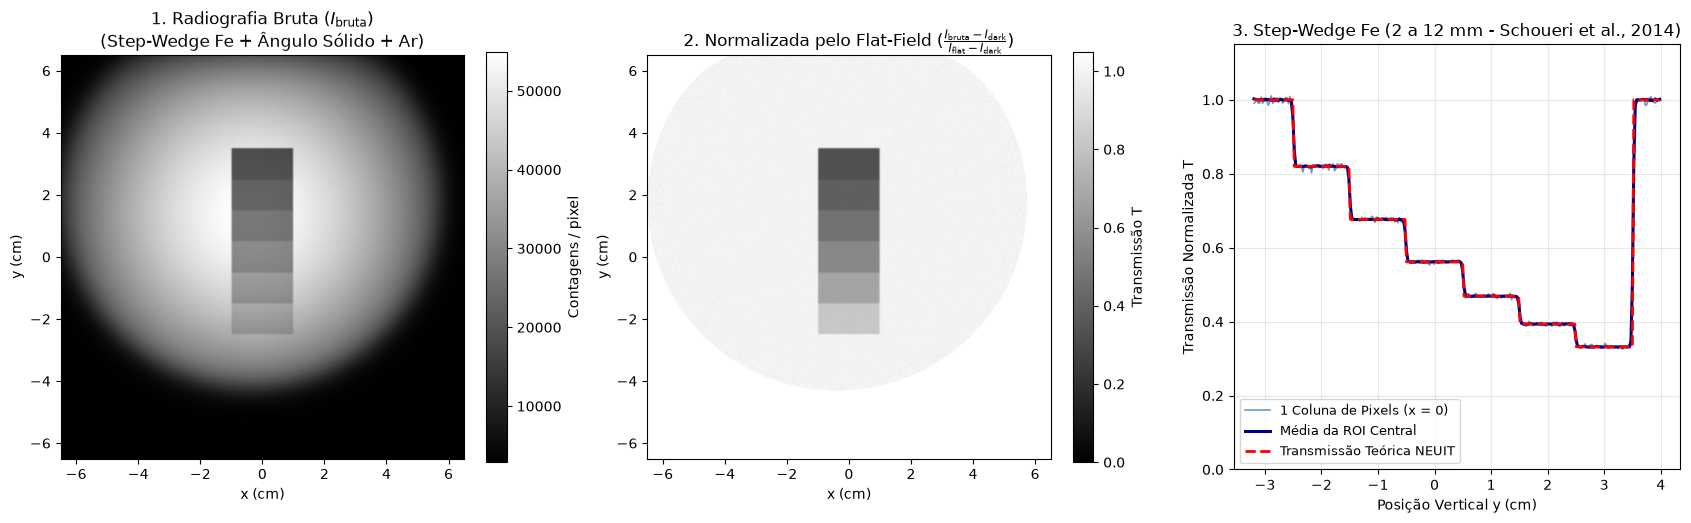

In [20]:
# 6.1 Normalização Experimental: T = (I_bruta - I_dark) / (I_flat - I_dark)
denom_flat = np.clip(flat_image - I_dark, 1.0, None)
img_normalizada = np.clip((img_bruta - I_dark) / denom_flat, 0.0, 1.2)
img_normalizada[mascara_flat_beam == 77] = np.nan  # Aplica a máscara exata do flat-beam (R > 6.231 cm)

# 6.2 Visualização: Radiografia Bruta vs. Normalizada vs. Perfil Quantitativo nos Degraus
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))

im0 = axes[0].imshow(img_bruta, cmap='gray', extent=ext, origin='lower')
axes[0].set_title(r"1. Radiografia Bruta ($I_{\mathrm{bruta}}$)" + "\n(Step-Wedge Fe + Ângulo Sólido + Ar)")
axes[0].set_xlabel("x (cm)")
axes[0].set_ylabel("y (cm)")
plt.colorbar(im0, ax=axes[0], fraction=0.046, label="Contagens / pixel")

im1 = axes[1].imshow(img_normalizada, cmap='gray', vmin=0, vmax=1.05, extent=ext, origin='lower')
axes[1].set_title(r"2. Normalizada pelo Flat-Field ($\frac{I_{\mathrm{bruta}} - I_{\mathrm{dark}}}{I_{\mathrm{flat}} - I_{\mathrm{dark}}}$)")
axes[1].set_xlabel("x (cm)")
axes[1].set_ylabel("y (cm)")
plt.colorbar(im1, ax=axes[1], fraction=0.046, label="Transmissão T")

# Perfil vertical passando pelo centro do Step-Wedge (x = 0 cm)
col_centro = N_pix // 2
mask_y = (coords >= -3.2) & (coords <= 4.0)
T_teorica_y = np.trapz(
    pesos_frio[:, None] * np.exp(-sigmas_lmbda['Fe'][:, None] * d_Fe_2d[mask_y, col_centro][None, :]),
    lmbda_A, axis=0
)

axes[2].plot(coords[mask_y], img_normalizada[mask_y, col_centro], color='steelblue', lw=1.2, alpha=0.8, label="1 Coluna de Pixels (x = 0)")
axes[2].plot(coords[mask_y], np.nanmean(img_normalizada[mask_y, col_centro-25:col_centro+25], axis=1), color='navy', lw=2.2, label="Média da ROI Central")
axes[2].plot(coords[mask_y], T_teorica_y, 'r--', lw=2, label="Transmissão Teórica NEUIT")
axes[2].set_title("3. Step-Wedge Fe (2 a 12 mm - Schoueri et al., 2014)")
axes[2].set_xlabel("Posição Vertical y (cm)")
axes[2].set_ylabel("Transmissão Normalizada T")
axes[2].set_ylim(0, 1.15)
axes[2].legend(fontsize=9)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## Parte 7: Exportação da Imagem em 32 bits (`.tiff`) e Máscara do Objeto (`labels`)
Salva a radiografia simulada em formato **TIFF de 32 bits** (`float32`) e gera a máscara de segmentação pixel a pixel seguindo o dicionário de classes do arquivo `labels` (`ferro = 5`, `fundo = 0`, etc.).

Arquivos para U-Net salvos com sucesso em 'saida_tiff/':
  - saida_tiff/radiografia_bruta_32bits.tiff (dtype=float32, shape=(512, 512))
  - saida_tiff/mascara_ferro_label5.tiff  (dtype=uint8, valores únicos na máscara: [0 5])


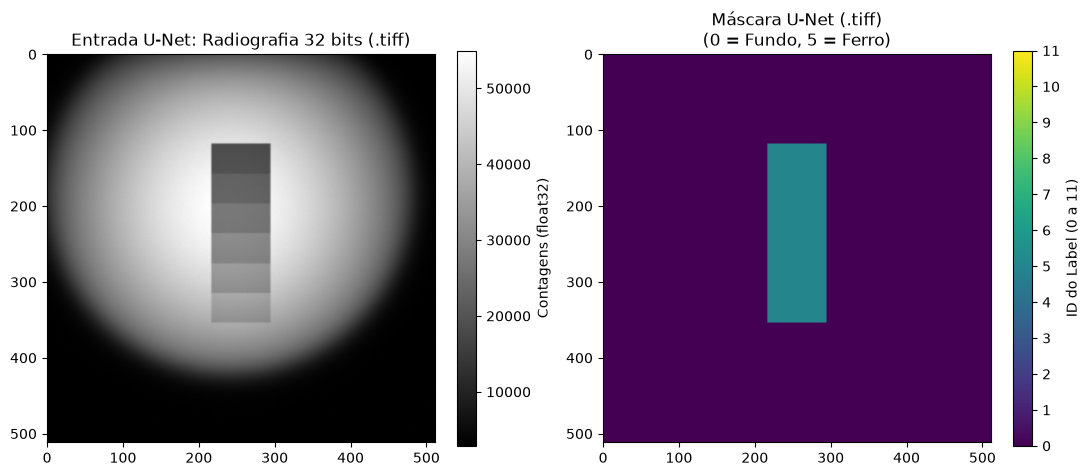

In [21]:
import os
from PIL import Image

# 7.1 Dicionário de classes conforme o arquivo 'labels' em anexo (0 = fundo/ar)
LABELS_MATERIAIS = {
    'fundo':   0,
    'bronze':  1,
    'cedro':   2,
    'chumbo':  3,
    'cobre':   4,
    'ferro':   5,
    'grafite': 6,
    'latao':   7,
    'lucite':  8,
    'p_sabao': 9,
    'prata':   10,
    'ouro':    11,
}

# 7.2 Construção da máscara para U-Net (somente 0 = fundo e o label do material respectivo):
mascara_objeto = np.full((N_pix, N_pix), LABELS_MATERIAIS['fundo'], dtype=np.uint8)  # 0 = fundo
mascara_objeto[d_Fe_2d > 0] = LABELS_MATERIAIS['ferro']                              # 5 = ferro

# 7.3 Preparação das matrizes para exportação (orientação de imagem: linha 0 no topo com np.flipud)
img_bruta_32b = np.flipud(img_bruta).astype(np.float32)       # Imagem de entrada em 32 bits (float32)
mascara_8b    = np.flipud(mascara_objeto).astype(np.uint8)    # Máscara para U-Net (apenas 0 e 5)

# 7.4 Salvando a radiografia em 32 bits (.tiff) e a máscara da U-Net (.tiff) usando Pillow (PIL)
pasta_saida = "saida_tiff"
os.makedirs(pasta_saida, exist_ok=True)

caminho_bruta_tiff = os.path.join(pasta_saida, "radiografia_bruta_32bits.tiff")
caminho_mask_tiff  = os.path.join(pasta_saida, "mascara_ferro_label5.tiff")

# mode='F' -> TIFF de 32-bit ponto flutuante (IEEE754 float32)
# mode='L' -> TIFF de 8-bit inteiro sem sinal (uint8, ideal para classes 0..11 na U-Net)
Image.fromarray(img_bruta_32b, mode='F').save(caminho_bruta_tiff, format='TIFF')
Image.fromarray(mascara_8b,    mode='L').save(caminho_mask_tiff,  format='TIFF')

print(f"Arquivos para U-Net salvos com sucesso em '{pasta_saida}/':")
print(f"  - {caminho_bruta_tiff} (dtype={img_bruta_32b.dtype}, shape={img_bruta_32b.shape})")
print(f"  - {caminho_mask_tiff}  (dtype={mascara_8b.dtype}, valores únicos na máscara: {np.unique(mascara_8b)})")

# 7.5 Visualização lado a lado: Imagem 32 bits (Entrada) vs. Máscara U-Net (Fundo = 0, Ferro = 5)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))

im0 = axes[0].imshow(img_bruta_32b, cmap='gray')
axes[0].set_title("Entrada U-Net: Radiografia 32 bits (.tiff)")
plt.colorbar(im0, ax=axes[0], fraction=0.046, label="Contagens (float32)")

im1 = axes[1].imshow(mascara_8b, cmap='viridis', vmin=0, vmax=11)
axes[1].set_title("Máscara U-Net (.tiff)\n(0 = Fundo, 5 = Ferro)")
plt.colorbar(im1, ax=axes[1], fraction=0.046, ticks=range(12), label="ID do Label (0 a 11)")

plt.tight_layout()
plt.show()